# Tu primer programa LangGraph

Importante: LangGraph no es un modelo de IA. Es el motor que organiza la ejecución. Puedes utilizarlo sin LLM, como haremos en esta primera clase.

````bash
uv init mi-primer-agente

uv add --dev ipykernel
uv run python -c "import ipykernel; print(ipykernel.__version__)"

uv add langgraph
````


# Entender el codigo

## El State: la memoria de trabajo

El State es un diccionario estructurado que transporta los datos a lo largo del grafo.

````python 
class AgentState(TypedDict):
    servidor: str
    cpu: int
    diagnostico: str
````

cada nodo recibe el estado y devuelve únicamente los campos que necesita actualizar. LangGraph integra esas actualizaciones en el estado compartido.

## Los Nodes: funciones Python
Un nodo puede realizar operaciones reales: SSH, consultas a Grafana, conexiones a Oracle, invocaciones a un LLM, etc.
````python
def consultar_cpu(state: AgentState):
    return {"cpu": 95}
````
Le indican a LangGraph que ejecute primero consultar_cpu, luego analizar_cpu y finalmente termine.
Por ahora son conexiones fijas. Más adelante aprenderemos las conditional edges, donde la siguiente ruta depende del resultado.
## Las Edges: conexiones entre nodos

````python
builder.add_edge(START, "consultar_cpu")
builder.add_edge("consultar_cpu", "analizar_cpu")
builder.add_edge("analizar_cpu", END)
````

## Compilar y ejecutar
Construye el grafo ejecutable a partir de su definición.
````python
graph = builder.compile()
````
Ejecuta el grafo con los datos iniciales y devuelve el estado resultante.
````python
resultado = graph.invoke({...})
````

# Resumen de la primera clase

| Concepto | Qué debes recordar |
|---|---|
| `StateGraph` | Define la estructura del grafo. |
| `State` | Contiene los datos compartidos. |
| `add_node()` | Añade una función al grafo. |
| `add_edge()` | Conecta dos nodos. |
| `START` y `END` | Inicio y final del flujo. |
| `compile()` | Prepara el grafo ejecutable. |
| `invoke()` | Ejecuta el grafo. |

# programa LangGraph
Vamos a crear un grafo que simule una alerta de CPU.

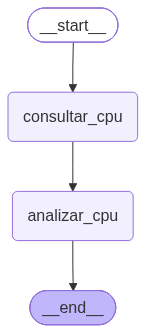

Consultando CPU de srv-linux-01

RESULTADO FINAL:
{'servidor': 'srv-linux-01', 'cpu': 95, 'diagnostico': 'CRITICAL: CPU muy alta'}


In [1]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


# 1. Definir el estado compartido
class AgentState(TypedDict):
    servidor: str
    cpu: int
    diagnostico: str


# 2. Primer nodo: consultar CPU
def consultar_cpu(state: AgentState):
    print(f"Consultando CPU de {state['servidor']}")

    # Simulamos un valor de CPU
    return {"cpu": 95}


# 3. Segundo nodo: analizar CPU
def analizar_cpu(state: AgentState):
    cpu = state["cpu"]

    if cpu > 90:
        resultado = "CRITICAL: CPU muy alta"
    else:
        resultado = "OK: CPU normal"

    return {"diagnostico": resultado}


# 4. Construir el grafo
builder = StateGraph(AgentState)

builder.add_node("consultar_cpu", consultar_cpu)
builder.add_node("analizar_cpu", analizar_cpu)


# 5. Conectar los nodos
builder.add_edge(START, "consultar_cpu")
builder.add_edge("consultar_cpu", "analizar_cpu")
builder.add_edge("analizar_cpu", END)


# 6. Compilar
graph = builder.compile()


# 7. Visualizar el grafo en Jupyter Notebook
display(Image(graph.get_graph().draw_mermaid_png()))


# 8. Ejecutar
resultado = graph.invoke({
    "servidor": "srv-linux-01",
    "cpu": 0,
    "diagnostico": ""
})

print("\nRESULTADO FINAL:")
print(resultado)